# # 05 · Regression models, logistic regression and clustering (M5)
#
# **Questions**
# 1. Which factors explain PM2.5? We predict log PM2.5 from the gaseous pollutants (NO2, SO2) plus state,
#    season and location type. This is **less circular** than modelling AQI, because AQI is computed from the
#    pollutants themselves.
# 2. For completeness, how well do the pollutants explain AQI? (Circular by construction — shown and stated.)
# 3. Can we classify days as "Moderate or worse" (AQI > 100) vs "Satisfactory or better" with logistic
#    regression? And "Poor or worse" (AQI > 200)?
# 4. Bonus: do stations fall into natural clusters by pollution profile?
#
# Random seed 42 for every split and clustering.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score, silhouette_score)
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from IPython.display import display

from src.style import apply_style, save_fig, save_table, STATE_COLORS, LABELS, ACCENT, FIGSIZE, NEUTRAL
from src.data import load_clean, POLLUTANTS, STATE_ORDER, SEASON_ORDER

apply_style()
pd.set_option("display.width", 170, "display.max_columns", 30)
SEED = 42
df = load_clean()
df["season"] = df["season"].astype(str)
df["location_class"] = df["location_class"].replace({"Mixed (RIRUO)": "Mixed"})

def vif_table(model):
    X = pd.DataFrame(model.model.exog, columns=model.model.exog_names)
    return pd.DataFrame({"variable": X.columns[1:],
                         "VIF": [variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])]})

# ## 1. Multiple linear regression: log PM2.5
#
# We build up models and compare them with AIC (lower is better) and adjusted R².
# Reference categories: state = Gujarat, season = Monsoon, location = Residential.

In [2]:
FORMULAS = {
    "M1 gases": "log_PM25 ~ log_NO2 + log_SO2",
    "M2 + state": "log_PM25 ~ log_NO2 + log_SO2 + C(state)",
    "M3 + season": "log_PM25 ~ log_NO2 + log_SO2 + C(state) + C(season, Treatment('Monsoon'))",
    "M4 + location": "log_PM25 ~ log_NO2 + log_SO2 + C(state) + C(season, Treatment('Monsoon')) + C(location_class, Treatment('Residential'))",
    "M5 + state×season": "log_PM25 ~ log_NO2 + log_SO2 + C(state) * C(season, Treatment('Monsoon')) + C(location_class, Treatment('Residential'))",
}
models = {k: smf.ols(f, data=df).fit() for k, f in FORMULAS.items()}
comp = pd.DataFrame({k: {"k (params)": int(m.df_model) + 1, "R²": m.rsquared, "adj R²": m.rsquared_adj,
                          "AIC": m.aic, "BIC": m.bic, "F": m.fvalue, "F p": m.f_pvalue}
                     for k, m in models.items()}).T
comp["ΔAIC vs best"] = comp["AIC"] - comp["AIC"].min()
display(comp.round(3))
save_table(comp.round(4), "m5_model_comparison", index=True)

,k (params),R²,adj R²,AIC,BIC,F,F p,ΔAIC vs best
M1 gases,3.0,0.165,0.164,4755.702,4774.413,371.956,0.0,2161.695
M2 + state,5.0,0.395,0.394,3541.942,3573.126,615.332,0.0,947.934
M3 + season,8.0,0.468,0.467,3058.725,3108.621,474.368,0.0,464.718
M4 + location,10.0,0.486,0.485,2935.155,2997.524,395.800,0.0,341.147
M5 + state×season,16.0,0.532,0.530,2594.008,2693.799,284.907,0.0,0.000


WindowsPath('C:/Users/Advay/Desktop/ASM/Asm project/results/m5_model_comparison.csv')

# Nested-model F-tests (does each added block improve fit significantly?):

In [3]:
names = list(models)
nested = []
for a, b in zip(names[:-1], names[1:]):
    f, p, ddf = models[b].compare_f_test(models[a])
    nested.append({"from": a, "to": b, "F": f, "df added": ddf, "p": p})
nested = pd.DataFrame(nested)
display(nested.round(4))
save_table(nested.round(5), "m5_nested_f_tests")

,from,to,F,df added,p
0,M1 gases,M2 + state,717.5104,2.0,0.0
1,M2 + state,M3 + season,173.7326,3.0,0.0
2,M3 + season,M4 + location,64.7027,2.0,0.0
3,M4 + location,M5 + state×season,61.4352,6.0,0.0


WindowsPath('C:/Users/Advay/Desktop/ASM/Asm project/results/m5_nested_f_tests.csv')

# ### Backward elimination by AIC (starting from M4, main effects)

In [4]:
terms = ["log_NO2", "log_SO2", "C(state)", "C(season, Treatment('Monsoon'))", "C(location_class, Treatment('Residential'))"]
current = terms.copy()
best_aic = smf.ols("log_PM25 ~ " + " + ".join(current), data=df).fit().aic
log = [{"step": 0, "model": " + ".join(current), "AIC": best_aic}]
improved = True
while improved and len(current) > 1:
    improved = False
    trials = {t: smf.ols("log_PM25 ~ " + " + ".join([c for c in current if c != t]), data=df).fit().aic for t in current}
    t_best = min(trials, key=trials.get)
    if trials[t_best] < best_aic:
        current.remove(t_best); best_aic = trials[t_best]; improved = True
        log.append({"step": len(log), "model": " + ".join(current), "AIC": best_aic})
display(pd.DataFrame(log))
print("No term removed → every block lowers AIC" if len(log) == 1 else "Terms removed, see table")

,step,model,AIC
0,0,"log_NO2 + log_SO2 + C(state) + C(season, Treat...",2935.154561


No term removed → every block lowers AIC


# ### Final model (M4): coefficients with station-clustered robust standard errors
#
# M5 (with the interaction) has the lowest AIC, but M4 is kept as the *interpretable* final model: its
# main effects read directly, and the interaction is described by M3's two-way ANOVA.
# Repeated measurements of the same station are correlated (Durbin-Watson ≈ 0.7 below) and variances differ
# across states (Breusch-Pagan), so we report **cluster-robust standard errors with stations as clusters**,
# which handle both problems. Because the outcome is log PM2.5:
# - for **log NO2**, the coefficient is an *elasticity*: a 1% rise in NO2 goes with a β% rise in PM2.5;
# - for a **category**, exp(β) is the ratio of geometric-mean PM2.5 versus the reference category.

In [5]:
final = models["M4 + location"]
codes = pd.factorize(df["station"])[0]
final_r = final.get_robustcov_results(cov_type="cluster", groups=codes)
coef = pd.DataFrame({"coef": final_r.params, "robust SE": final_r.bse, "t": final_r.tvalues, "p": final_r.pvalues,
                     "CI low": final_r.conf_int()[:, 0], "CI high": final_r.conf_int()[:, 1]},
                    index=final.params.index)
coef["exp(coef)"] = np.exp(coef["coef"])
# standardised coefficients for the continuous predictors
for v in ["log_NO2", "log_SO2"]:
    coef.loc[v, "std. beta"] = coef.loc[v, "coef"] * df[v].std() / df["log_PM25"].std()
coef.index = (coef.index.str.replace(r"C\(season, Treatment\('Monsoon'\)\)", "season", regex=True)
                        .str.replace(r"C\(location_class, Treatment\('Residential'\)\)", "location", regex=True)
                        .str.replace("C(state)", "state", regex=False))
display(coef.round(4))
save_table(coef.round(5), "m5_final_ols_coefficients", index=True)
print(f"R² = {final.rsquared:.3f}, adj R² = {final.rsquared_adj:.3f}, F({final.df_model:.0f}, {final.df_resid:.0f}) = {final.fvalue:.1f}, p < 0.001, n = {int(final.nobs)}")

,coef,robust SE,t,p,CI low,CI high,exp(coef),std. beta
Intercept,2.0101,0.3218,6.2460,0.0000,1.3683,2.6520,7.4644,NaN
state[T.Odisha],0.7441,0.0777,9.5798,0.0000,0.5892,0.8990,2.1045,NaN
state[T.West Bengal],0.9571,0.1096,8.7306,0.0000,0.7384,1.1757,2.6040,NaN
season[T.Post-monsoon],0.2550,0.0455,5.5976,0.0000,0.1641,0.3458,1.2904,NaN
season[T.Summer],0.1825,0.0339,5.3884,0.0000,0.1150,0.2501,1.2003,NaN
season[T.Winter],0.3538,0.0477,7.4214,0.0000,0.2587,0.4489,1.4245,NaN
location[T.Industrial],0.1491,0.0726,2.0529,0.0438,0.0042,0.2939,1.1607,NaN
location[T.Mixed],0.1266,0.0450,2.8132,0.0064,0.0369,0.2164,1.1350,NaN
log_NO2,0.0742,0.1022,0.7256,0.4705,-0.1297,0.2781,1.0770,0.0722
log_SO2,0.3224,0.0478,6.7506,0.0000,0.2272,0.4177,1.3805,0.5469


R² = 0.486, adj R² = 0.485, F(9, 3768) = 395.8, p < 0.001, n = 3778


# ### Diagnostics: VIF, Breusch-Pagan, residual normality, influential points

In [6]:
vif = vif_table(final)
vif["variable"] = (vif.variable.str.replace(r"C\(season, Treatment\('Monsoon'\)\)", "season", regex=True)
                   .str.replace(r"C\(location_class, Treatment\('Residential'\)\)", "location", regex=True))
display(vif.round(2))
save_table(vif.round(3), "m5_vif")
bp = het_breuschpagan(final.resid, final.model.exog)
infl = final.get_influence()
cooks = infl.cooks_distance[0]
n, k = int(final.nobs), int(final.df_model) + 1
diag = pd.Series({"Breusch-Pagan LM": bp[0], "BP p": bp[1],
                  "Residual skewness": stats.skew(final.resid), "Residual excess kurtosis": stats.kurtosis(final.resid),
                  "Jarque-Bera p": stats.jarque_bera(final.resid).pvalue,
                  "Max Cook's D": cooks.max(), "# Cook's D > 4/n": int((cooks > 4 / n).sum()),
                  "Durbin-Watson": sm.stats.durbin_watson(final.resid)})
display(diag.round(4).to_frame("value"))
save_table(diag.round(5).to_frame("value"), "m5_ols_diagnostics", index=True)

# Sensitivity: refit without high-influence points
keep = cooks <= 4 / n
final_trim = smf.ols(FORMULAS["M4 + location"], data=df[keep]).fit()
print(f"Without {(~keep).sum()} influential points: R² = {final_trim.rsquared:.3f}; "
      f"log_NO2 coef {final.params['log_NO2']:.3f} → {final_trim.params['log_NO2']:.3f}; "
      f"log_SO2 coef {final.params['log_SO2']:.3f} → {final_trim.params['log_SO2']:.3f}")

,variable,VIF
0,C(state)[T.Odisha],3.07
1,C(state)[T.West Bengal],3.29
2,season[T.Post-monsoon],1.36
3,season[T.Summer],1.43
4,season[T.Winter],1.59
5,location[T.Industrial],1.10
6,location[T.Mixed],1.48
7,log_NO2,2.58
8,log_SO2,2.07


,value
Breusch-Pagan LM,324.5005
BP p,0.0000
Residual skewness,-0.4485
Residual excess kurtosis,1.1417
Jarque-Bera p,0.0000
Max Cook's D,0.0070
# Cook's D > 4/n,180.0000
Durbin-Watson,0.7125


Without 180 influential points: R² = 0.560; log_NO2 coef 0.074 → -0.019; log_SO2 coef 0.322 → 0.329


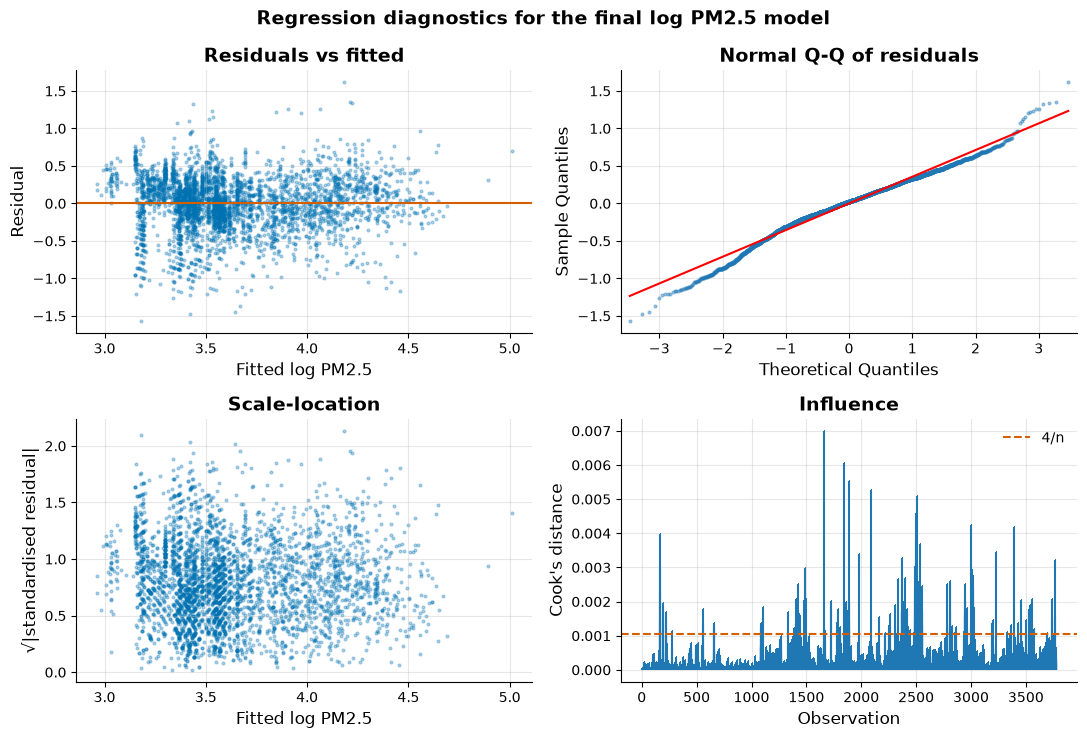

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
axes[0, 0].scatter(final.fittedvalues, final.resid, s=4, alpha=.3, color="#0072B2")
axes[0, 0].axhline(0, color=ACCENT); axes[0, 0].set_xlabel("Fitted log PM2.5"); axes[0, 0].set_ylabel("Residual")
axes[0, 0].set_title("Residuals vs fitted")
sm.qqplot(final.resid, line="s", ax=axes[0, 1], markersize=2, alpha=.4); axes[0, 1].set_title("Normal Q-Q of residuals")
axes[1, 0].scatter(final.fittedvalues, np.sqrt(np.abs(infl.resid_studentized_internal)), s=4, alpha=.3, color="#0072B2")
axes[1, 0].set_xlabel("Fitted log PM2.5"); axes[1, 0].set_ylabel("√|standardised residual|"); axes[1, 0].set_title("Scale-location")
axes[1, 1].stem(np.arange(n), cooks, markerfmt=",", basefmt=" ")
axes[1, 1].axhline(4 / n, color=ACCENT, ls="--", label="4/n"); axes[1, 1].set_xlabel("Observation"); axes[1, 1].set_ylabel("Cook's distance")
axes[1, 1].set_title("Influence"); axes[1, 1].legend()
fig.suptitle("Regression diagnostics for the final log PM2.5 model", fontweight="bold", fontsize=14)
fig.tight_layout(); save_fig(fig, "m5_ols_diagnostics"); plt.show()

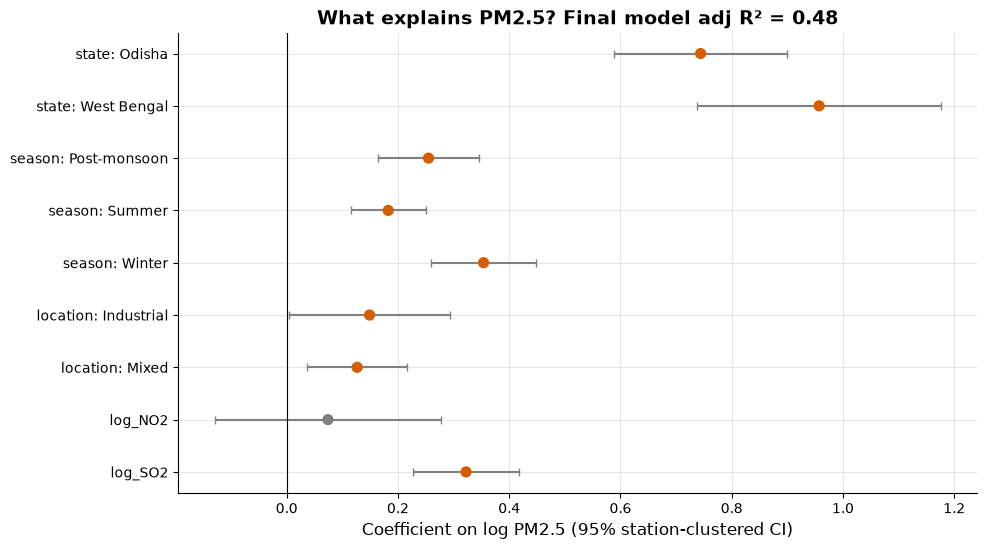

In [8]:
plot_coef = coef.drop("Intercept").copy()
plot_coef["label"] = plot_coef.index.str.replace("[T.", ": ", regex=False).str.replace("]", "", regex=False)
plot_coef = plot_coef.iloc[::-1]
fig, ax = plt.subplots(figsize=FIGSIZE)
cols = [ACCENT if p < .05 else NEUTRAL for p in plot_coef.p]
ax.errorbar(plot_coef["coef"], range(len(plot_coef)), xerr=[plot_coef["coef"] - plot_coef["CI low"], plot_coef["CI high"] - plot_coef["coef"]],
            fmt="none", ecolor="grey", capsize=3)
ax.scatter(plot_coef["coef"], range(len(plot_coef)), color=cols, s=50, zorder=3)
ax.axvline(0, color="black", lw=.8)
ax.set_yticks(range(len(plot_coef)), plot_coef.label)
ax.set_xlabel("Coefficient on log PM2.5 (95% station-clustered CI)")
ax.set_title(f"What explains PM2.5? Final model adj R² = {final.rsquared_adj:.2f}")
fig.tight_layout(); save_fig(fig, "m5_coefficients"); plt.show()

# ## 2. Using M4's factor scores (and the circular AQI model)
#
# **AQI model.** AQI is the maximum of the pollutant sub-indices, so regressing AQI on the pollutants only
# shows that the formula works. We fit it to make the circularity explicit and to show the multicollinearity
# problem (PM10 and PM2.5 are highly correlated), and refit with M4's two factor scores, which are
# uncorrelated by construction.

In [9]:
aqi_raw = smf.ols("AQI ~ PM10 + PM25 + NO2 + SO2", data=df).fit()
fs = pd.read_csv("../results/m4_factor_scores.csv")
df["F1_particulate"], df["F2_gas"] = fs["F1_particulate"].values, fs["F2_gas"].values
aqi_fs = smf.ols("AQI ~ F1_particulate + F2_gas", data=df).fit()
aqi_tbl = pd.DataFrame({
    "AQI ~ pollutants": {"R²": aqi_raw.rsquared, "adj R²": aqi_raw.rsquared_adj, "AIC": aqi_raw.aic,
                         "max VIF": vif_table(aqi_raw).VIF.max()},
    "AQI ~ factor scores": {"R²": aqi_fs.rsquared, "adj R²": aqi_fs.rsquared_adj, "AIC": aqi_fs.aic,
                            "max VIF": vif_table(aqi_fs).VIF.max()}}).T
display(aqi_tbl.round(3))
display(vif_table(aqi_raw).round(2))
print(aqi_raw.summary().tables[1])
save_table(aqi_tbl.round(4), "m5_aqi_models", index=True)
print("Share of days where each pollutant sets the AQI:")
print(df.AQI_driver.value_counts(normalize=True).round(3))

,R²,adj R²,AIC,max VIF
AQI ~ pollutants,0.925,0.925,30723.550,3.431
AQI ~ factor scores,0.781,0.781,34747.218,1.000


,variable,VIF
0,PM10,3.06
1,PM25,3.43
2,NO2,1.44
3,SO2,1.08


                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -5.3806      0.646     -8.327      0.000      -6.647      -4.114
PM10           0.5820      0.010     58.131      0.000       0.562       0.602
PM25           1.1105      0.017     65.927      0.000       1.077       1.144
NO2            0.0072      0.020      0.367      0.714      -0.031       0.046
SO2            0.3072      0.040      7.629      0.000       0.228       0.386
Share of days where each pollutant sets the AQI:
AQI_driver
PM10    0.769
PM25    0.225
NO2     0.005
Name: proportion, dtype: float64


# ## 3. Logistic regression
#
# **Outcome A (primary):** AQI > 100, i.e. "Moderate or worse" vs "Satisfactory or better" (30.5% of days).
# **Outcome B (secondary):** AQI > 200, "Poor or worse" (5.6% of days). There are no such days in Gujarat or
in the monsoon, which causes perfect separation, so model B drops state and uses a single
`cold_season` indicator (Winter + Post-monsoon vs Summer + Monsoon).
#
# Predictors deliberately **exclude PM10 and PM2.5**, because they define AQI. We use log NO2, log SO2,
# season, location type and state, i.e. information that does not directly compute the outcome.
# 70/30 stratified train/test split (seed 42). Odds ratios from the training fit; performance on the test set.

In [10]:
df["moderate_plus"] = (df.AQI > 100).astype(int)
df["poor_plus"] = (df.AQI > 200).astype(int)
df["cold_season"] = df.season.isin(["Winter", "Post-monsoon"]).astype(int)
print(pd.crosstab(df.season, df.poor_plus))
print(df[["moderate_plus", "poor_plus"]].mean().round(3))

LOGIT_A = ("moderate_plus ~ log_NO2 + log_SO2 + C(state) + C(season, Treatment('Monsoon'))"
           " + C(location_class, Treatment('Residential'))")
LOGIT_B = ("poor_plus ~ log_NO2 + log_SO2 + cold_season"
           " + C(location_class, Treatment('Residential'))")

def fit_logit(formula, outcome, name):
    train, test = train_test_split(df, test_size=.3, random_state=SEED, stratify=df[outcome])
    m = smf.logit(formula, data=train).fit(disp=0)
    prob = m.predict(test)
    thr = 0.5 if train[outcome].mean() > .2 else train[outcome].mean()  # rare outcome: threshold at prevalence
    pred = (prob >= thr).astype(int)
    cm = confusion_matrix(test[outcome], pred)
    tn, fp, fn, tp = cm.ravel()
    perf = pd.Series({"model": name, "train n": len(train), "test n": len(test), "prevalence": df[outcome].mean(),
                      "threshold": thr, "accuracy": accuracy_score(test[outcome], pred),
                      "sensitivity (recall)": tp / (tp + fn), "specificity": tn / (tn + fp),
                      "precision": precision_score(test[outcome], pred, zero_division=0),
                      "F1": f1_score(test[outcome], pred), "ROC-AUC": roc_auc_score(test[outcome], prob),
                      "McFadden pseudo-R²": m.prsquared, "LR chi² p": m.llr_pvalue,
                      "baseline accuracy (always majority)": max(test[outcome].mean(), 1 - test[outcome].mean())})
    # grouped robustness: hold out whole stations
    gss = GroupShuffleSplit(n_splits=1, test_size=.3, random_state=SEED)
    tr_idx, te_idx = next(gss.split(df, groups=df.station))
    mg = smf.logit(formula, data=df.iloc[tr_idx]).fit(disp=0)
    perf["ROC-AUC (held-out stations)"] = roc_auc_score(df.iloc[te_idx][outcome], mg.predict(df.iloc[te_idx]))
    ors = pd.DataFrame({"odds ratio": np.exp(m.params), "CI low": np.exp(m.conf_int()[0]),
                        "CI high": np.exp(m.conf_int()[1]), "p": m.pvalues})
    ors.index = (ors.index.str.replace(r"C\(season, Treatment\('Monsoon'\)\)", "season", regex=True)
                 .str.replace(r"C\(location_class, Treatment\('Residential'\)\)", "location", regex=True)
                 .str.replace("C(state)", "state", regex=False))
    fpr, tpr, _ = roc_curve(test[outcome], prob)
    return m, perf, ors, cm, (fpr, tpr)

mA, perfA, orA, cmA, rocA = fit_logit(LOGIT_A, "moderate_plus", "A: AQI > 100")
mB, perfB, orB, cmB, rocB = fit_logit(LOGIT_B, "poor_plus", "B: AQI > 200")
display(orA.round(3)); display(orB.round(3))
perf = pd.concat([perfA, perfB], axis=1).T
display(perf)
save_table(orA.round(4), "m5_logit_A_odds_ratios", index=True)
save_table(orB.round(4), "m5_logit_B_odds_ratios", index=True)
save_table(perf, "m5_logit_performance")
print("Confusion matrix A (rows = actual 0/1, cols = predicted 0/1):\n", cmA)
print("Confusion matrix B:\n", cmB)

poor_plus        0    1
season                 
Monsoon       1086    0
Post-monsoon   550   62
Summer         866   17
Winter        1066  131
moderate_plus    0.305
poor_plus        0.056
dtype: float64


,odds ratio,CI low,CI high,p
Intercept,0.001,0.000,0.002,0.000
state[T.Odisha],52.167,34.070,79.879,0.000
state[T.West Bengal],197.564,113.321,344.433,0.000
season[T.Post-monsoon],6.510,4.632,9.150,0.000
season[T.Summer],6.267,4.530,8.670,0.000
season[T.Winter],17.893,12.833,24.948,0.000
location[T.Industrial],1.544,1.213,1.964,0.000
location[T.Mixed],1.162,0.760,1.777,0.488
log_NO2,0.749,0.539,1.041,0.086
log_SO2,3.309,2.791,3.923,0.000


,odds ratio,CI low,CI high,p
Intercept,0.000,0.000,0.000,0.000
location[T.Industrial],2.075,1.328,3.242,0.001
location[T.Mixed],0.598,0.314,1.139,0.118
log_NO2,23.255,15.135,35.730,0.000
log_SO2,2.652,1.802,3.902,0.000
cold_season,9.209,5.153,16.457,0.000


,model,train n,test n,prevalence,threshold,accuracy,sensitivity (recall),specificity,precision,F1,ROC-AUC,McFadden pseudo-R²,LR chi² p,baseline accuracy (always majority),ROC-AUC (held-out stations)
0,A: AQI > 100,2644,1134,0.305188,0.5,0.809524,0.589595,0.906091,0.733813,0.653846,0.845996,0.32846,0.0,0.694885,0.745713
1,B: AQI > 200,2644,1134,0.055585,0.055598,0.86067,0.857143,0.860878,0.26601,0.406015,0.917945,0.41399,0.0,0.944444,0.724201


Confusion matrix A (rows = actual 0/1, cols = predicted 0/1):
 [[714  74]
 [142 204]]
Confusion matrix B:
 [[922 149]
 [  9  54]]


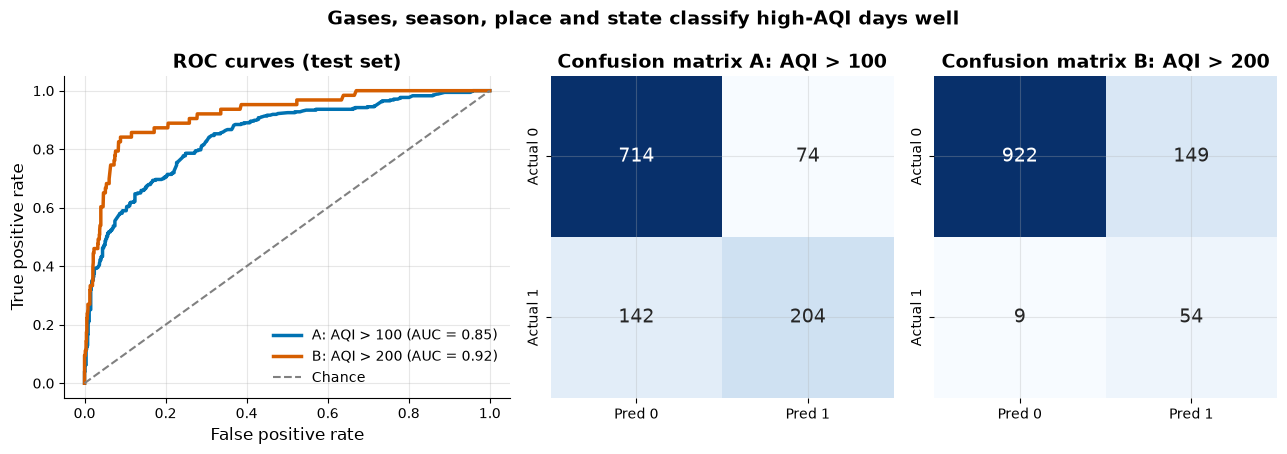

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.3, 1, 1]})
for (fpr, tpr), perf_, c in [(rocA, perfA, "#0072B2"), (rocB, perfB, "#D55E00")]:
    axes[0].plot(fpr, tpr, lw=2.5, color=c, label=f"{perf_['model']} (AUC = {perf_['ROC-AUC']:.2f})")
axes[0].plot([0, 1], [0, 1], ls="--", color="grey", label="Chance")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].set_title("ROC curves (test set)")
axes[0].legend(loc="lower right")
for ax, cm, ttl in [(axes[1], cmA, "A: AQI > 100"), (axes[2], cmB, "B: AQI > 200")]:
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 14},
                xticklabels=["Pred 0", "Pred 1"], yticklabels=["Actual 0", "Actual 1"])
    ax.set_title(f"Confusion matrix {ttl}")
fig.suptitle("Gases, season, place and state classify high-AQI days well", fontweight="bold", fontsize=14)
fig.tight_layout(); save_fig(fig, "m5_logistic_roc_confusion"); plt.show()

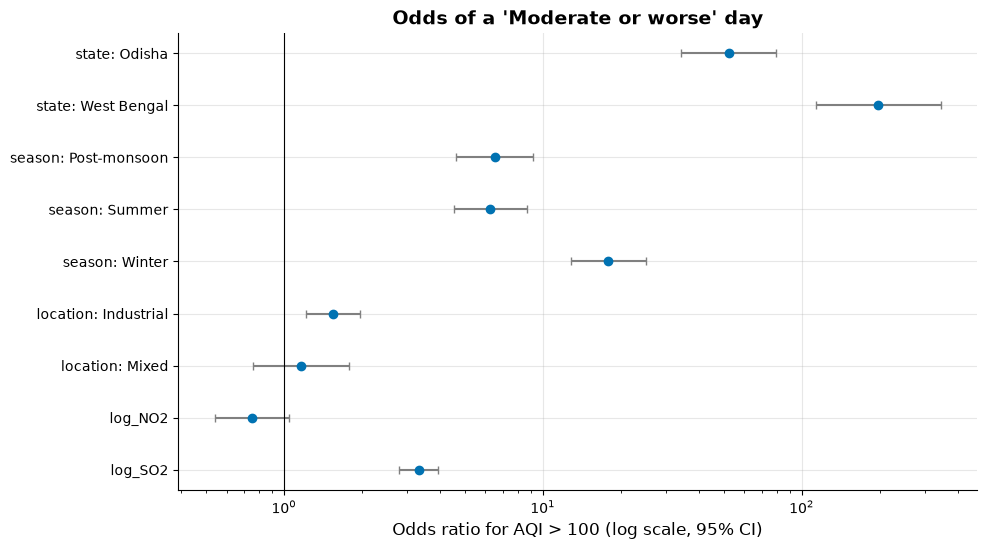

In [12]:
plot_or = orA.drop("Intercept").iloc[::-1]
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.errorbar(plot_or["odds ratio"], range(len(plot_or)),
            xerr=[plot_or["odds ratio"] - plot_or["CI low"], plot_or["CI high"] - plot_or["odds ratio"]],
            fmt="o", color="#0072B2", ecolor="grey", capsize=3)
ax.axvline(1, color="black", lw=.8); ax.set_xscale("log")
ax.set_yticks(range(len(plot_or)), plot_or.index.str.replace("[T.", ": ", regex=False).str.replace("]", "", regex=False))
ax.set_xlabel("Odds ratio for AQI > 100 (log scale, 95% CI)")
ax.set_title("Odds of a 'Moderate or worse' day")
fig.tight_layout(); save_fig(fig, "m5_logistic_odds_ratios"); plt.show()

# ## 4. Bonus: cluster analysis of stations by pollution profile
#
# Each station is described by its mean log concentration of the four pollutants (standardised).
# We try k = 2…6 with k-means (25 random starts, seed 42), pick the smallest k whose silhouette is within
# 0.02 of the best (parsimony: 71 stations do not support many tiny clusters), and confirm with Ward
# hierarchical clustering.

In [13]:
prof = df.groupby(["station", "state", "city", "location_class"])[[f"log_{p}" for p in POLLUTANTS]].mean().reset_index()
Zs = StandardScaler().fit_transform(prof[[f"log_{p}" for p in POLLUTANTS]])
sil = {}
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=25, random_state=SEED).fit(Zs)
    sil[k] = silhouette_score(Zs, km.labels_)
sil = pd.Series(sil, name="silhouette"); display(sil.round(3))
# parsimony rule: smallest k whose silhouette is within 0.02 of the best
k_best = int(min(k for k in sil.index if sil[k] >= sil.max() - 0.02))
km = KMeans(n_clusters=k_best, n_init=25, random_state=SEED).fit(Zs)
prof["cluster"] = km.labels_ + 1
hc = fcluster(linkage(Zs, "ward"), k_best, criterion="maxclust")
prof["ward_cluster"] = hc
agree = pd.crosstab(prof.cluster, prof.ward_cluster)
print(f"Best k = {k_best}; agreement k-means vs Ward:"); display(agree)

prof_means = prof.groupby("cluster")[[f"log_{p}" for p in POLLUTANTS]].mean().apply(np.exp).round(1)
prof_means.columns = [f"geo mean {p} (µg/m³)" for p in POLLUTANTS]
prof_means["n stations"] = prof.groupby("cluster").size()
display(prof_means)
display(pd.crosstab(prof.cluster, prof.state)); display(pd.crosstab(prof.cluster, prof.location_class))
save_table(sil.round(4).to_frame(), "m5_cluster_silhouette", index=True)
save_table(prof_means, "m5_cluster_profiles", index=True)
save_table(prof[["station", "state", "city", "location_class", "cluster", "ward_cluster"]], "m5_station_clusters")

2    0.412
3    0.477
4    0.527
5    0.526
6    0.538
Name: silhouette, dtype: float64

Best k = 4; agreement k-means vs Ward:


ward_cluster,1,2,3,4
cluster,,,,
1,0,0,36,0
2,0,0,0,12
3,0,11,0,2
4,9,0,1,0


,geo mean SO2 (µg/m³),geo mean NO2 (µg/m³),geo mean PM10 (µg/m³),geo mean PM25 (µg/m³),n stations
cluster,,,,,
1,13.7,19.6,88.2,30.8,36
2,6.3,35.7,103.7,55.9,12
3,2.3,18.3,65.4,24.1,13
4,3.1,11.9,88.0,46.3,10


state,Gujarat,Odisha,West Bengal
cluster,,,
1,32,4,0
2,0,5,7
3,0,13,0
4,0,10,0


location_class,Industrial,Mixed,Residential
cluster,,,
1,8,13,15
2,5,1,6
3,1,0,12
4,3,0,7


WindowsPath('C:/Users/Advay/Desktop/ASM/Asm project/results/m5_station_clusters.csv')

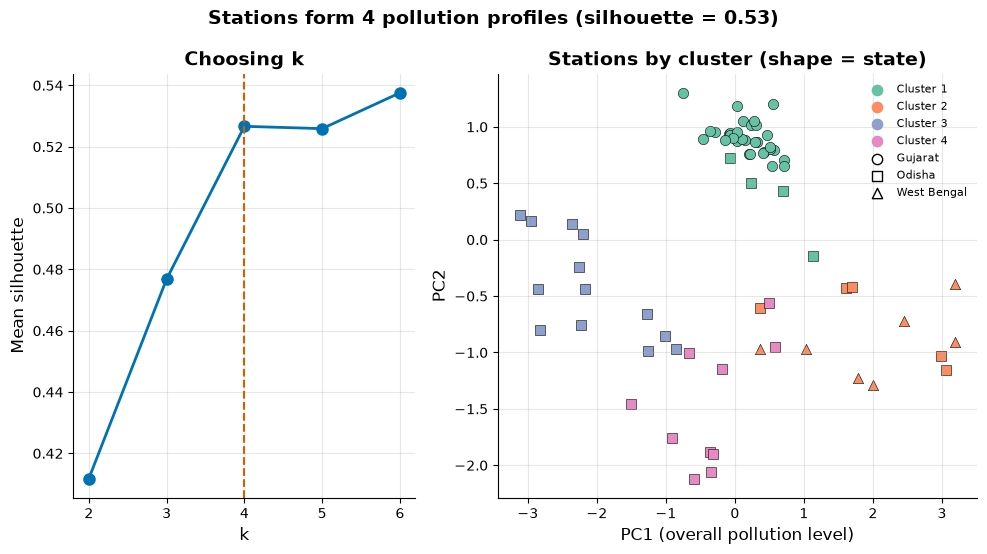

In [14]:
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].plot(sil.index, sil.values, "o-", color="#0072B2", lw=2, ms=8)
axes[0].axvline(k_best, color=ACCENT, ls="--"); axes[0].set_xlabel("k"); axes[0].set_ylabel("Mean silhouette")
axes[0].set_title("Choosing k")
pc = np.linalg.svd(Zs - Zs.mean(0), full_matrices=False)
xy = (Zs - Zs.mean(0)) @ pc[2].T[:, :2]
xy *= np.sign(pc[2][:2].sum(axis=1))  # orient PCs so higher = more pollution
markers = {"Gujarat": "o", "Odisha": "s", "West Bengal": "^"}
pal = sns.color_palette("Set2", k_best)
for s, mk in markers.items():
    for c in range(1, k_best + 1):
        m = (prof.state == s) & (prof.cluster == c)
        axes[1].scatter(xy[m, 0], xy[m, 1], marker=mk, s=55, color=pal[c - 1], edgecolor="k", lw=.4)
for c in range(1, k_best + 1):
    axes[1].scatter([], [], color=pal[c - 1], s=55, label=f"Cluster {c}")
for s, mk in markers.items():
    axes[1].scatter([], [], marker=mk, color="white", edgecolor="k", s=55, label=s)
axes[1].set_xlabel("PC1 (overall pollution level)"); axes[1].set_ylabel("PC2")
axes[1].set_title("Stations by cluster (shape = state)"); axes[1].legend(fontsize=8, loc="best")
fig.suptitle(f"Stations form {k_best} pollution profiles (silhouette = {sil[k_best]:.2f})", fontweight="bold", fontsize=14)
fig.tight_layout(); save_fig(fig, "m5_station_clusters"); plt.show()

# ## 5. Conclusions (slides 11–12)
#
# **Multiple regression (log PM2.5).** Each block of predictors improves the model (nested F-tests all
# p < 0.001; backward AIC elimination removes nothing). R² rises from 0.16 (gases only) to **0.49**
# (gases + state + season + location; adj R² 0.48, F(9, 3768) = 396, p < 0.001) and 0.53 with the
# state × season interaction. Holding the others constant (station-clustered 95% CIs):
# - Odisha ×2.10 (1.80–2.46) and West Bengal ×2.60 (2.09–3.24) the PM2.5 of Gujarat;
# - Winter ×1.42, Post-monsoon ×1.29, Summer ×1.20 the monsoon level;
# - Industrial sites ×1.16 (p = 0.04) and mixed sites ×1.14 residential sites;
# - SO2 elasticity 0.32: doubling SO2 goes with ~25% more PM2.5 (standardised β = 0.55, the largest);
# - NO2 is not significant once state is in the model and station clustering is accounted for (p = 0.47).
#
# **Diagnostics.** VIFs ≤ 3.3 (no problematic multicollinearity once PM10 is excluded). Breusch-Pagan
# p < 0.001 (heteroscedastic) and Durbin-Watson 0.71 (repeated station measurements) → we use
# station-clustered robust SEs. Residuals are mildly heavy-tailed (skew −0.45, excess kurtosis 1.1),
# acceptable at this n. No single point is influential (max Cook's D = 0.007); removing the 180 points with
# D > 4/n leaves the SO2 effect unchanged (0.32 → 0.33).
#
# **AQI model (circular).** Pollutants explain 92% of AQI, as they must; factor scores explain 78% with
# VIF = 1. PM10 sets the AQI on 77% of days and PM2.5 on 23%. This is a check of the formula, not a finding.
#
# **Logistic A (AQI > 100).** Test accuracy 81% vs 69% for always guessing "satisfactory"; sensitivity
# 59%, specificity 91%, **ROC-AUC 0.85** (0.75 when whole stations are held out). Winter raises the odds
# ~18× vs the monsoon; West Bengal and Odisha have far higher odds than Gujarat (which almost never exceeds
# 100); industrial sites 1.5×; doubling SO2 multiplies the odds by ~2.3.
#
# **Logistic B (AQI > 200, rare).** At a threshold equal to the 5.6% prevalence: sensitivity 86%,
# specificity 86%, precision 27%, **ROC-AUC 0.92** (0.72 on held-out stations). Cold season OR = 9.2;
# doubling NO2 multiplies the odds by ~8.9; industrial sites 2.1×.
#
# **Clustering.** k = 4 (silhouette 0.53) gives interpretable station groups: (1) all 32 Gujarat stations plus 4 Odisha ones —
# moderate, steady PM with the highest SO2; (2) the Kolkata area plus Odisha's industrial hubs (Angul,
# Talcher, Cuttack) — highest PM2.5 and NO2; (3) Odisha's cleaner coastal and residential towns (Puri,
# Konark, Bhubaneswar, Berhampur) — lowest PM; (4) Odisha's mining/steel belt (Rourkela, Kalinga Nagar,
# Keonjhar) — high PM2.5 with low gases. Clusters follow geography and industry more than the
# industrial/residential label.